# Comparativo Multiversões: Random Forest vs XGBoost vs LightGBM
Neste notebook, testamos múltiplas variantes arquiteturais e hiperparâmetros de cada algoritmo contra o desbalanceamento financeiro de ~5,5% do dataset.

Os testes incluem:
- **Random Forest**: Variação de profundidade (`max_depth`), amostragem (`n_estimators`), e pesos de classes balanceados (`balanced` e `balanced_subsample`).
- **XGBoost**: Variação da taxa de aprendizado (`learning_rate`), pesos de custo assimétricos (`scale_pos_weight`) e controle de complexidade de árvores.
- **LightGBM**: Variação de `is_unbalance=True`, `scale_pos_weight` e limites de folhas (`num_leaves`).
- **Threshold Tuning**: Varredura de probabilidade do modelo campeão para maximizar o F1-Score e Recall sem destruir a Precisão.

In [21]:
# Instalação e bibliotecas necessárias
!pip install kagglehub scikit-learn xgboost lightgbm seaborn matplotlib pandas numpy -q

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
import warnings
warnings.filterwarnings('ignore')

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc
)

## 1. Carregamento dos Dados e Engenharia de Atributos
Utilizamos uma amostra representativa e aplicamos a engenharia de variáveis com `LabelEncoder`, mantendo a densidade e evitando a dispersão matemática.

In [22]:
path = kagglehub.dataset_download("nafiulislam490/bank-transaction-fraud-detection-dataset")
df = pd.read_csv(f"{path}/bank_fraud.csv")
#.sample(n=500000, random_state=42)

df_feat = df.copy()

# 1. Codificação Categórica densa
cat_cols = ['country', 'city', 'merchant_category', 'payment_method', 'device_type']
for col in cat_cols:
    df_feat[col] = LabelEncoder().fit_transform(df_feat[col].astype(str))

# 2. Feature Engineering Financeiro
df_feat['amount_to_balance_ratio'] = df_feat['transaction_amount'] / (df_feat['account_balance'] + 1.0)
df_feat['txn_velocity_kmh'] = df_feat['distance_from_home_km'] / (df_feat['time_since_last_txn_hrs'] + 0.1)
df_feat['risk_flags_sum'] = (
    df_feat['is_night_transaction'] +
    df_feat['is_international'] +
    (df_feat['failed_attempts'] > 0).astype(int) +
    df_feat['pin_changed_recently']
)

# 3. Limpeza de colunas redundantes ou de vazamento
drop_cols = ['transaction_id', 'customer_id', 'transaction_date', 'transaction_time', 'fraud_type']
df_feat.drop(columns=[c for c in drop_cols if c in df_feat.columns], inplace=True)

X = df_feat.drop('is_fraud', axis=1)
y = df_feat['is_fraud']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

print(f"Conjunto de Treino: {X_train.shape[0]:,} | Conjunto de Teste: {X_test.shape[0]:,}")
print(f"Taxa Real de Fraudes: {y.mean() * 100:.2f}%")

Conjunto de Treino: 750,000 | Conjunto de Teste: 250,000
Taxa Real de Fraudes: 5.53%


## 2. Definição das Versões e Torneio de Algoritmos
Criamos múltiplas versões especializadas para avaliar como cada arquitetura lida com o desbalanceamento.

In [23]:
# Cálculo da razão de desbalanceamento para os modelos de Gradient Boosting
pos_weight = (len(y_train) - sum(y_train)) / sum(y_train)

model_versions = {
    # --- Versões de Random Forest ---
    "Random Forest v1 (Depth=10, Balanced)": RandomForestClassifier(
        n_estimators=100, max_depth=10, class_weight='balanced', random_state=42, n_jobs=-1
    ),
    "Random Forest v2 (Depth=15, Subsample Balanced)": RandomForestClassifier(
        n_estimators=150, max_depth=15, min_samples_split=5, class_weight='balanced_subsample', random_state=42, n_jobs=-1
    ),
    "Random Forest v3 (Depth=8, Conservative)": RandomForestClassifier(
        n_estimators=120, max_depth=8, class_weight='balanced', random_state=42, n_jobs=-1
    ),
    
    # --- Versões de XGBoost ---
    "XGBoost v1 (Standard Scale Weight, lr=0.1)": XGBClassifier(
        n_estimators=150, max_depth=6, learning_rate=0.1, scale_pos_weight=pos_weight, eval_metric='logloss', random_state=42, n_jobs=-1
    ),
    "XGBoost v2 (Deep, Moderate Weight, lr=0.05)": XGBClassifier(
        n_estimators=200, max_depth=8, learning_rate=0.05, scale_pos_weight=pos_weight*0.6, eval_metric='logloss', random_state=42, n_jobs=-1
    ),
    "XGBoost v3 (Shallow, Heavy Regularization)": XGBClassifier(
        n_estimators=120, max_depth=4, learning_rate=0.08, scale_pos_weight=pos_weight, reg_alpha=1.0, reg_lambda=2.0, eval_metric='logloss', random_state=42, n_jobs=-1
    ),
    
    # --- Versões de LightGBM ---
    "LightGBM v1 (is_unbalance=True, leaves=31)": LGBMClassifier(
        n_estimators=150, learning_rate=0.08, num_leaves=31, is_unbalance=True, random_state=42, n_jobs=-1, verbose=-1
    ),
    "LightGBM v2 (Scale Weight, Fast lr=0.1)": LGBMClassifier(
        n_estimators=180, learning_rate=0.1, num_leaves=20, scale_pos_weight=pos_weight, random_state=42, n_jobs=-1, verbose=-1
    ),
    "LightGBM v3 (Deep, Moderate Weight, leaves=63)": LGBMClassifier(
        n_estimators=200, learning_rate=0.05, num_leaves=63, scale_pos_weight=pos_weight*0.6, random_state=42, n_jobs=-1, verbose=-1
    )
}

results = []
fitted_models = {}

print("Treinando e avaliando todas as versões...\n")

for name, model in model_versions.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    
    fitted_models[name] = (model, y_pred, y_prob)
    
    results.append({
        'Modelo/Versão': name,
        'Acurácia': accuracy_score(y_test, y_pred),
        'Precisão': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1-Score': f1_score(y_test, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, y_prob)
    })

df_leaderboard = pd.DataFrame(results).sort_values(by='F1-Score', ascending=False).reset_index(drop=True)
print("=== PLACAR GERAL DAS VERSÕES ===")
display(df_leaderboard)

Treinando e avaliando todas as versões...

=== PLACAR GERAL DAS VERSÕES ===


,Modelo/Versão,Acurácia,Precisão,Recall,F1-Score,ROC-AUC
0,"LightGBM v3 (Deep, Moderate Weight, leaves=63)",0.795948,0.125742,0.452367,0.196785,0.721990
1,"XGBoost v2 (Deep, Moderate Weight, lr=0.05)",0.811400,0.126563,0.408933,0.193300,0.717331
2,"XGBoost v3 (Shallow, Heavy Regularization)",0.672212,0.104251,0.649631,0.179669,0.723724
3,"Random Forest v2 (Depth=15, Subsample Balanced)",0.738460,0.107986,0.514189,0.178488,0.704943
4,"LightGBM v1 (is_unbalance=True, leaves=31)",0.662452,0.102536,0.658969,0.177459,0.723335
5,"LightGBM v2 (Scale Weight, Fast lr=0.1)",0.660776,0.102063,0.659042,0.176753,0.723294
6,"XGBoost v1 (Standard Scale Weight, lr=0.1)",0.668912,0.102309,0.642102,0.176496,0.720096
7,"Random Forest v1 (Depth=10, Balanced)",0.597484,0.092735,0.715506,0.164190,0.717702
8,"Random Forest v3 (Depth=8, Conservative)",0.590176,0.092308,0.726437,0.163802,0.716990


## 3. Calibração de Limiar (Threshold Tuning) no Campeão do Torneio
Pegamos a versão que obteve a melhor capacidade preditiva e ajustamos seu limiar de probabilidade para encontrar o equilíbrio entre falsos positivos e capturas de fraude.

In [24]:
best_name = df_leaderboard.iloc[0]['Modelo/Versão']
best_model, _, best_probs = fitted_models[best_name]

# Varredura do melhor threshold de corte
thresholds = np.linspace(0.1, 0.9, 81)
f1_list = [f1_score(y_test, (best_probs >= t).astype(int), zero_division=0) for t in thresholds]
optimal_threshold = thresholds[np.argmax(f1_list)]
y_pred_final = (best_probs >= optimal_threshold).astype(int)

print(f"Campeão Geral: {best_name}")
print(f"Limiar Ótimo de Corte: {optimal_threshold:.2f}\n")
print("Métricas Finais do Campeão:")
print(f"Acurácia:  {accuracy_score(y_test, y_pred_final):.4f}")
print(f"Precisão:  {precision_score(y_test, y_pred_final):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_final):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred_final):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, best_probs):.4f}")

Campeão Geral: LightGBM v3 (Deep, Moderate Weight, leaves=63)
Limiar Ótimo de Corte: 0.50

Métricas Finais do Campeão:
Acurácia:  0.7959
Precisão:  0.1257
Recall:    0.4524
F1-Score:  0.1968
ROC-AUC:   0.7220


## 4. Matriz de Confusão e Curva ROC do Campeão

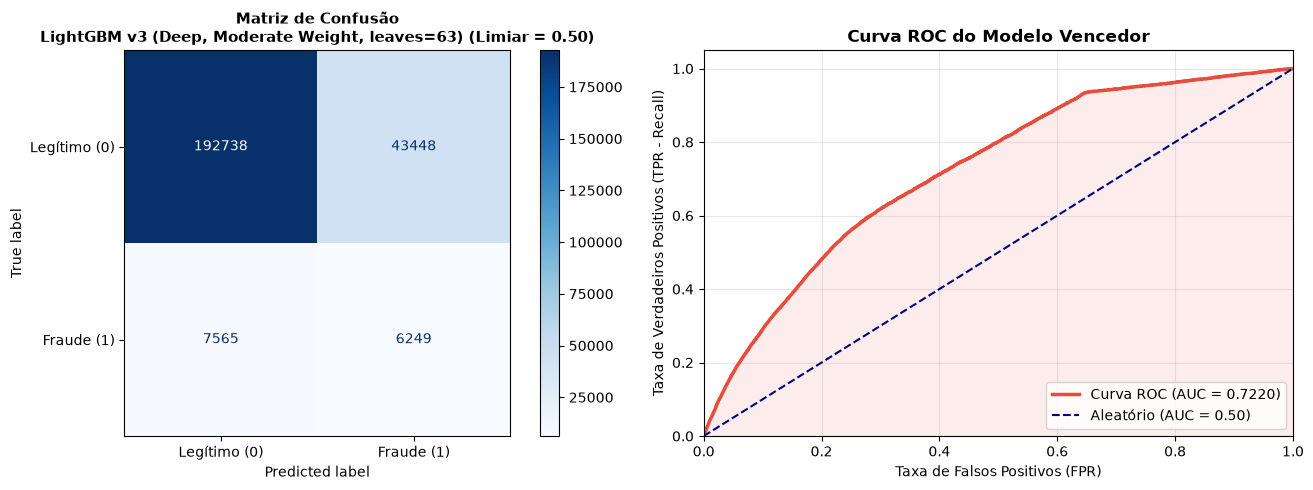

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Matriz de Confusão
cm = confusion_matrix(y_test, y_pred_final)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Legítimo (0)', 'Fraude (1)'])
disp.plot(cmap='Blues', ax=axes[0], values_format='d')
axes[0].set_title(f'Matriz de Confusão\n{best_name} (Limiar = {optimal_threshold:.2f})', fontsize=11, fontweight='bold')
axes[0].grid(False)

# Curva ROC
fpr, tpr, _ = roc_curve(y_test, best_probs)
roc_auc_val = auc(fpr, tpr)
axes[1].plot(fpr, tpr, color='#e74c3c', lw=2.5, label=f'Curva ROC (AUC = {roc_auc_val:.4f})')
axes[1].plot([0, 1], [0, 1], color='navy', lw=1.5, linestyle='--', label='Aleatório (AUC = 0.50)')
axes[1].fill_between(fpr, tpr, alpha=0.1, color='#e74c3c')
axes[1].set_xlim([0.0, 1.0])
axes[1].set_ylim([0.0, 1.05])
axes[1].set_xlabel('Taxa de Falsos Positivos (FPR)')
axes[1].set_ylabel('Taxa de Verdadeiros Positivos (TPR - Recall)')
axes[1].set_title('Curva ROC do Modelo Vencedor', fontsize=12, fontweight='bold')
axes[1].legend(loc="lower right")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()